# Figure S25: CD40 colocalization locus

CD40 fine-mapped variants and trait colocalization across molecular assays.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_PAPER_ROOT` to the local
paper directory and `QTL_SOURCE_ROOT` to the figure checkout with staged inputs
and saved objects. For example, set these variables in the R session before
you run the cells. Paths can contain spaces.

Run the cells from top to bottom. The preparation links show the filters, joins,
and counts used to produce the plot inputs. New PDFs and PNGs go to
`notebook_outputs/`. The plotting scripts are in `notebooks/current/`.


## Prepare the plotted data

The scripts below prepare filters, joins, counts, and summaries from source result tables. Their inputs and execution order are listed in `preparation/manifest.json`. The source data are not included in Git.

- [fig4_loci](../../preparation/Fig4/build_loci.R): Build exclusive UpSet intersections from unique gene-trait membership and join CD40 SuSiE variants to participating GWAS/QTL signals with original locus offsets and credible-set labels.

Run `python3 tools/prepare_figure_data.py --list` from the repository root. Use the named root options described in `preparation/README.md`. Set `QTL_PREP_ROOT` to that run's output directory before running this notebook. The notebook then reads generated files from its `paper/` and `source/` folders. Other inputs and reference images still come from the original roots. A script with an unavailable source input is identified in the preparation manifest.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
prepared_root <- Sys.getenv("QTL_PREP_ROOT")
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  path <- file.path(root, relative)
  if (nzchar(prepared_root) && variable %in% c("QTL_PAPER_ROOT", "QTL_SOURCE_ROOT")) {
    namespace <- if (variable == "QTL_PAPER_ROOT") "paper" else "source"
    prepared_relative <- file.path(namespace, relative)
    generated <- file.path(prepared_root, prepared_relative)
    if (file.exists(generated)) {
      path <- generated
      variable <- "QTL_PREP_ROOT"
      relative <- prepared_relative
    }
  }
  if (!file.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  input_records[[paste(variable, relative, sep = ":")]] <- list(
    root = variable, path = relative, md5 = unname(tools::md5sum(path)))
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display reference Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Read the saved CD40 locus data

Rebuild S25 from the saved CD40 display data. The source already links QTL credible sets to GWAS trait and locus records. No harmonization, fine-mapping, or colocalization is repeated. PIP, RCP, and CLPP are posterior-based statistics, not association P values.


In [2]:
cd40 <- readr::read_tsv(source_file("Fig4/cd40_coloc_locus_plot_data.tsv"), show_col_types = FALSE)
trait_order <- c("systemic lupus erythematosus", "multiple sclerosis", "rheumatoid arthritis",
                 "inflammatory bowel disease", "crohn's disease", "ldl cholesterol", "monocyte")
trait_order <- trait_order[trait_order %in% cd40$trait]
cd40 <- cd40 %>% mutate(assay = factor(assay, c("eQTL", "pQTL", "sQTL")),
                        credible_set = factor(credible_set, unique(credible_set)))
stopifnot(nrow(cd40) > 0, all(cd40$gene == "ENSG00000101017"),
          all(dplyr::between(cd40$CLPP, 0, 1)), length(levels(cd40$credible_set)) <= 8L)


## Draw the locus display

The x axis gives hg38 chromosome 20 position. Color denotes assay, shape denotes the QTL credible set, and point size denotes signal-level CLPP. Saved offsets separate multiple GWAS loci within one trait row. The dashed line marks the CD40 transcription start site.


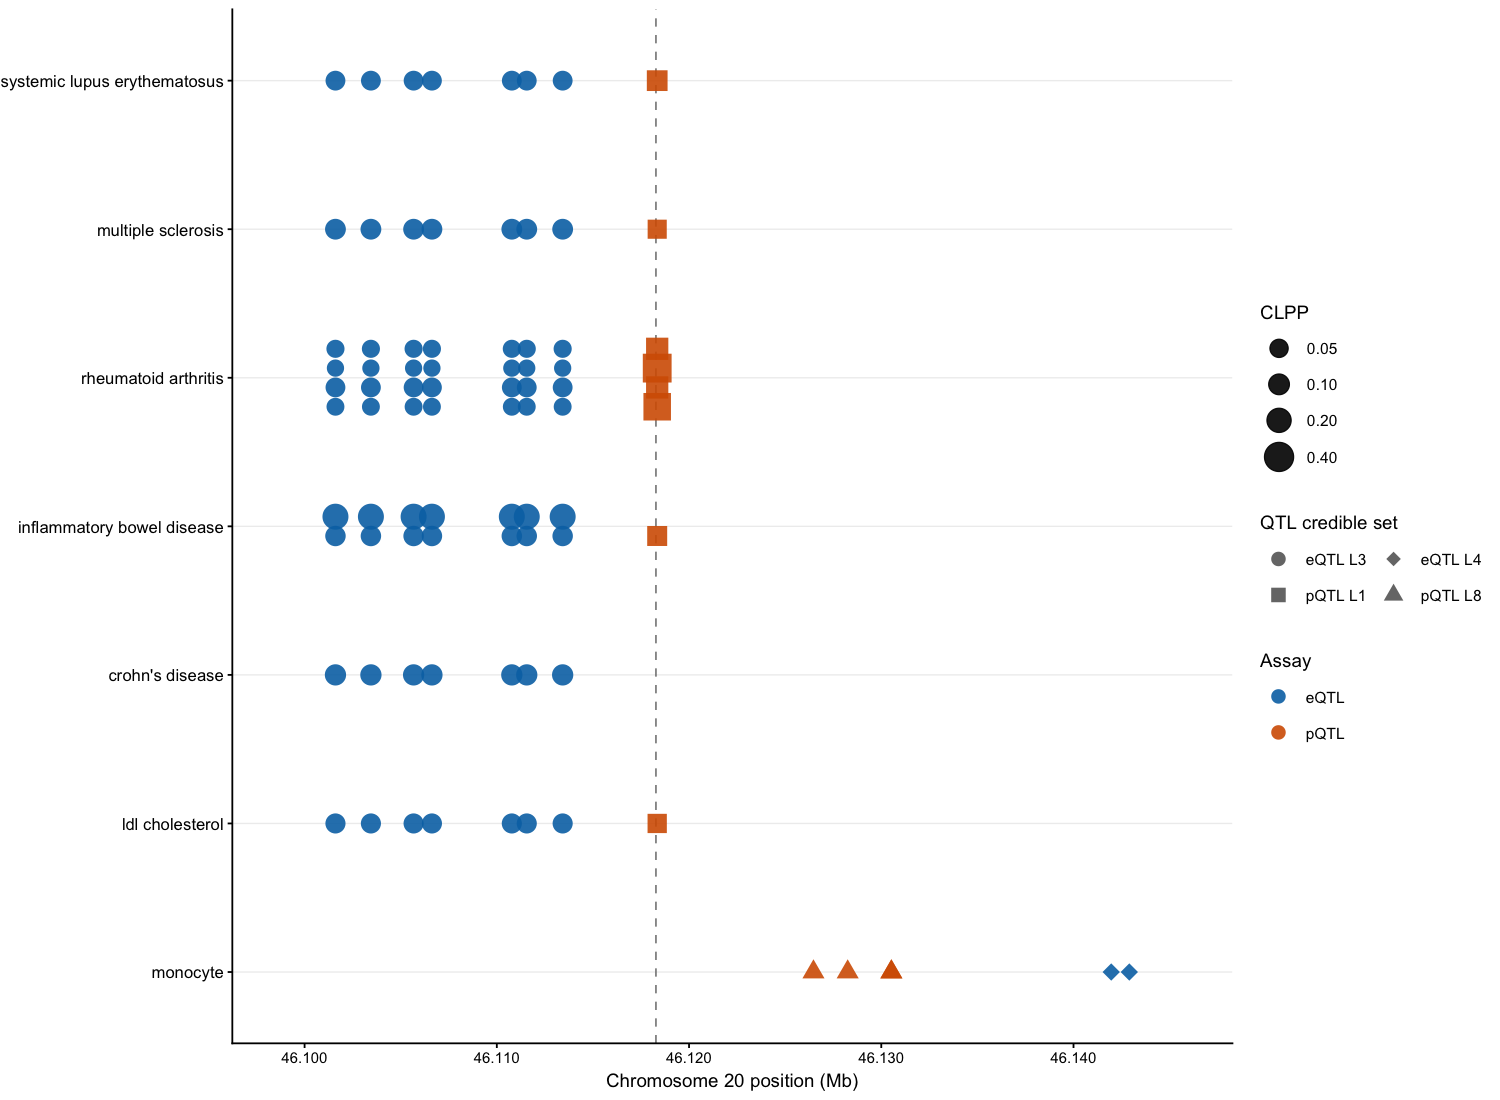

In [3]:
shapes <- setNames(c(16, 15, 18, 17, 8, 16, 15, 18)[seq_along(levels(cd40$credible_set))], levels(cd40$credible_set))
x_limits <- range(cd40$position_mb, finite = TRUE)
x_limits <- x_limits + c(-1, 1) * max(0.003, diff(x_limits) * 0.06)
figure <- ggplot(cd40, aes(position_mb, trait_y)) +
  geom_vline(xintercept = 46.118278, linetype = "dashed", linewidth = 0.35, colour = "grey50") +
  geom_point(aes(shape = credible_set, colour = assay, size = CLPP), alpha = 0.9) +
  scale_shape_manual(values = shapes, name = "QTL credible set") +
  scale_colour_manual(values = c(eQTL = "#0072B2", pQTL = "#D55E00", sQTL = "#009E73"), name = "Assay") +
  scale_size_continuous(range = c(2.5, 8.5), limits = c(0, 1), breaks = c(0.05, 0.1, 0.2, 0.4), name = "CLPP") +
  scale_x_continuous(limits = x_limits, breaks = pretty(x_limits, 6), labels = scales::label_number(accuracy = 0.001)) +
  scale_y_continuous(breaks = seq_along(trait_order), labels = rev(trait_order), expand = expansion(mult = c(0.08, 0.08))) +
  labs(x = "Chromosome 20 position (Mb)", y = NULL) +
  guides(shape = guide_legend(override.aes = list(size = 3, colour = "grey40"), nrow = 2),
         colour = guide_legend(override.aes = list(shape = 16, size = 3)), size = guide_legend(order = 4)) +
  theme_classic(base_size = 9) +
  theme(axis.text.y = element_text(size = 8), legend.text = element_text(size = 7.5),
        panel.grid.major.y = element_line(colour = "#EEEEEE", linewidth = 0.3))
print(figure)


## Save the figure and aggregate audit

Save a trait–assay summary rather than variant-level source records. Variant rows can repeat across GWAS loci and must not be interpreted as independent discoveries.


In [4]:
save_plot(figure, "supplements/S25", 230, 165)
readr::write_tsv(cd40 %>% group_by(trait, assay) %>%
                   summarise(variants = n_distinct(variant), credible_sets = n_distinct(qtl_cs),
                             loci = n_distinct(locus_key), maximum_CLPP = max(CLPP), .groups = "drop"),
                 output_file("supplements/S25_trait_assay_summary.tsv"))


Export aggregate plot: supplements/S25
